In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from xgboost import XGBClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import classification_report, hamming_loss
import joblib

In [2]:
# 1. Load the dataset
df = pd.read_csv("../data/processed/cbc_processed.csv")

In [3]:
# 2. Define features (ONLY raw lab values and gender)
feature_cols = ['WBC', 'RBC', 'HGB', 'HCT', 'MCV', 'MCH', 'MCHC', 'RDW', 'PLT', 'NE', 'LY', 'MO', 'EO', 'GENDER']
X = df[feature_cols]

In [4]:
# 3. Define target pathologies/diseases
pathology_cols = [
    'LEUKEMIA_SUSPECT', 'VIRAL_INF', 'BACTERIAL_INF', 'MONOCYTOSIS', 'EOSINOPHILIA',
    'CHRONIC_DISEASE_ANEMIA', 'THALASSEMIA_TRAIT', 'IRON_DEFICIENCY_ANEMIA', 'THROMBOCYTOPENIA', 'THROMBOCYTOSIS'
]

In [ ]:
y = df[pathology_cols]
# 4. Stratified Split (Crucial for keeping the rare disease rows balanced in train/test)
# Because it's multi-label, standard stratified split is tricky, so we use an iterative split or a solid random state with shuffle.
# We use a big train/test split of 60/40 in order to help train the model on the diseases that have the least numbers of cases.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

In [6]:
# 5. Define the Baseline Multi-Label Model

# Initialize our baseline multi-label model.
# We are intentionally setting hyperparameter constraints (like min_child_weight=5
# and max_depth=5) as a defense mechanism against rare-case overfitting, knowing
# that minority classes like Folate and B12 are highly vulnerable to noise.

disease_model = XGBClassifier(
    n_estimators=200,       # Number of sequential trees to build
    learning_rate=0.1,     # Step size shrinkage to prevent overfitting (lowers volatility)
    subsample=0.9,          # Row subsampling percentage per tree
    colsample_bytree=0.7,   # Column subsampling percentage per tree
    max_depth=5,            # Max depth of a tree. Deeper trees capture more complex rules but overfit easily
    min_child_weight=5,     # Minimum data points needed in a node to split. Higher values stop rare-case overfitting
    eval_metric='logloss',
    random_state=42,
    tree_method='hist')
multilabel_model = MultiOutputClassifier(disease_model)
multilabel_model.fit(X_train, y_train)

,estimator estimator: estimator objectAn estimator object implementing :term:`fit` and :term:`predict`.A :term:`predict_proba` method will be exposed only if `estimator` implementsit.,"XGBClassifier...ree=None, ...)"
,"n_jobs n_jobs: int or None, optional (default=None)The number of jobs to run in parallel.:meth:`fit`, :meth:`predict` and :meth:`partial_fit` (if supportedby the passed estimator) will be parallelized for each target.When individual estimators are fast to train or predict,using ``n_jobs > 1`` can result in slower performance dueto the parallelism overhead.``None`` means `1` unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all available processes / threads.See :term:`Glossary <n_jobs>` for more details... versionchanged:: 0.20 `n_jobs` default changed from `1` to `None`.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)Class labels.",list,"[array([0, 1]), array([0, 1]), array([0, 1]), array([0, 1]), ...]"
estimators_ estimators_: list of ``n_output`` estimatorsEstimators used for predictions.,list,"[XGBClassifier...ree=None, ...), XGBClassifier...ree=None, ...), XGBClassifier...ree=None, ...), XGBClassifier...ree=None, ...), ...]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[<U6](14,)","['WBC','RBC','HGB',...,'MO','EO','GENDER']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying `estimator` exposes such an attribute when fit... versionadded:: 0.24,int,14
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None


In [7]:
# 6. Evaluate Predictions
y_pred = multilabel_model.predict(X_test)
print("\n--- BASELINE EVALUATION COMPLETE ---\n")


--- BASELINE EVALUATION COMPLETE ---



In [11]:
# 7. Print performance per label
for i, col in enumerate(pathology_cols):
    print(f"================ PATHOLOGY: {col} ================")
    # Extract true values and predictions for this specific label
    true_labels = y_test[col]
    pred_labels = y_pred[:, i]

    print(classification_report(true_labels, pred_labels, zero_division=0))
    print(f"Total True Cases in Test Set: {true_labels.sum()}\n")

# Global multi-label loss (fraction of labels incorrectly predicted)
print(f"Overall Hamming Loss: {hamming_loss(y_test, y_pred):.4f}")

# Baseline performance reflects our preprocessing discoveries.
# The overlapping feature space between IDA and Chronic Disease Anemia leads to
# poor recall for ACD, causing the model to miss true positive cases. Concurrently,
# extreme class imbalance de-prioritizes rare targets, causing a recall dip in B12
# and a total classification failure on Folate Deficiency. This demonstrates why
# standard loss minimization cannot handle highly skewed clinical edge cases.

================ PATHOLOGY: LEUKEMIA_SUSPECT ================
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      6303
           1       1.00      1.00      1.00       930

    accuracy                           1.00      7233
   macro avg       1.00      1.00      1.00      7233
weighted avg       1.00      1.00      1.00      7233

Total True Cases in Test Set: 930

================ PATHOLOGY: VIRAL_INF ================
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      6965
           1       0.95      0.94      0.95       268

    accuracy                           1.00      7233
   macro avg       0.98      0.97      0.97      7233
weighted avg       1.00      1.00      1.00      7233

Total True Cases in Test Set: 268

================ PATHOLOGY: BACTERIAL_INF ================
              precision    recall  f1-score   support

           0       1.00      1.00      1.00  

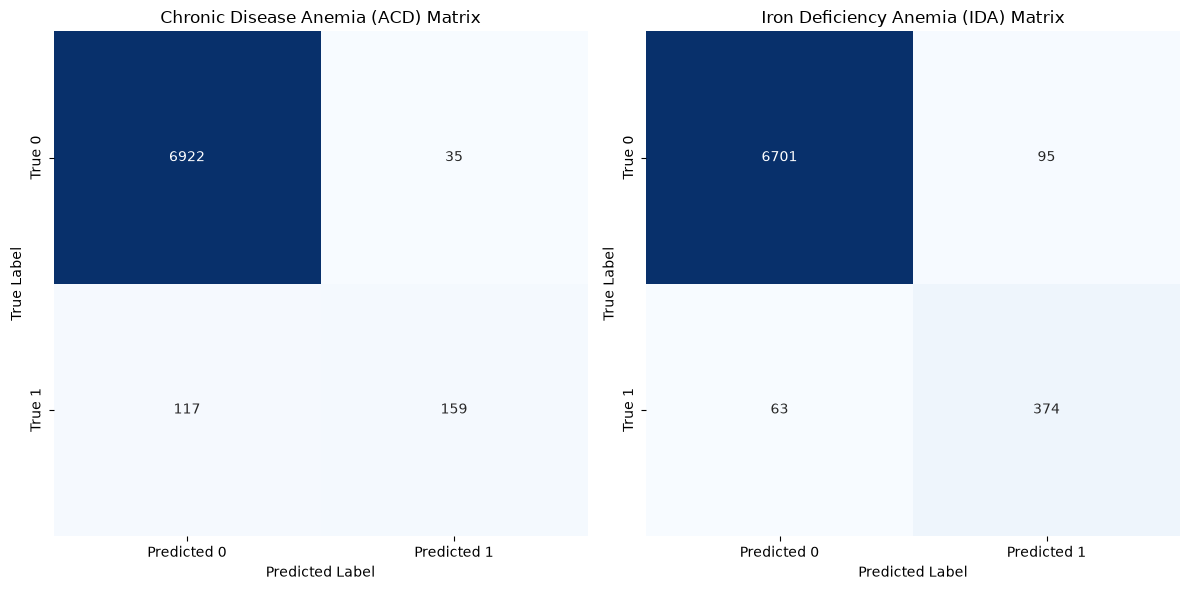

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Targets we want to investigate
target_pathologies = ['CHRONIC_DISEASE_ANEMIA', 'IRON_DEFICIENCY_ANEMIA']
display_names = ['Chronic Disease Anemia (ACD)', 'Iron Deficiency Anemia (IDA)']

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for idx, col in enumerate(target_pathologies):
    # Find the positional index of this column in your original pathology list
    col_idx = pathology_cols.index(col)

    # Calculate confusion matrix
    cm = confusion_matrix(y_test[col], y_pred[:, col_idx])

    # Plotting
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False,
                xticklabels=['Predicted 0', 'Predicted 1'],
                yticklabels=['True 0', 'True 1'])

    axes[idx].set_title(f'{display_names[idx]} Matrix')
    axes[idx].set_xlabel('Predicted Label')
    axes[idx].set_ylabel('True Label')

plt.tight_layout()
plt.show()

In [13]:
# Save the model
model_path = "../models/multi_label_disease_model.joblib"
joblib.dump(multilabel_model, model_path)
print(f"Model successfully saved to: {model_path}")

Model successfully saved to: ../models/multi_label_disease_model.joblib
